# 03 - Keyword Prediction: Improved Baseline
## TF-IDF → LSA → LinearSVC + OneVsRest

**Pipeline overview:**
1. Text feature preparation (title + abstract + introduction)
2. MultiLabelBinarizer → sparse binary target matrix
3. TF-IDF vectorization
4. LSA (Latent Semantic Analysis) dimensionality reduction
5. OneVsRestClassifier with LinearSVC + class_weight balancing
6. Threshold tuning → best micro-F1

**Comparison to v0 baseline (title+abstract, LogisticRegression C=1.0):**

| Experiment | micro-F1 | macro-F1 | Note |
|------------|----------|----------|------|
| title+abstract, LR C=1.0 | 0.205 | 0.031 | Baseline v0 |
| title+abstract+intro, LR C=0.1 | 0.006 | 0.000 | C too small → over-regularized |
| title+abstract+intro, LinearSVC + LSA | TBD | TBD | this notebook |

## 0 - Imports & Data

In [1]:
#!pip install scikit-learn

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import re
from pathlib import Path

from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.multiclass import OneVsRestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score
from sklearn.pipeline import Pipeline
import scipy.sparse as sp

CWD = Path.cwd()
PROJECT_ROOT = CWD if (CWD / 'big_data').exists() else CWD.parent

df = pd.read_pickle(PROJECT_ROOT / 'big_data' / 'baseline' / 'pickle' / 'clean_articles.pkl')
print(f"Loaded: {df.shape[0]} articles, {df.shape[1]} columns")
df.columns

Loaded: 34128 articles, 20 columns


Index(['filename', 'pmcid', 'doi', 'journal', 'year', 'authors', 'title',
       'keywords', 'abstract', 'introduction', 'methods', 'results',
       'discussion', 'conclusion', 'tables', 'metadata_junk', 'kwd_lst',
       'kwd_lst_cl', 'n_keywords', 'keywords_filtered'],
      dtype='str')

## 1 - Input Features

We concatenate **title + abstract + introduction** as input text.

> **Why more text?**
> The title is short but keyword-dense. The abstract summarises the work.
> The introduction provides broader context and often repeats key concepts.
> More signal → better TF-IDF term weights → better classification.

Avg text length (chars): 3158


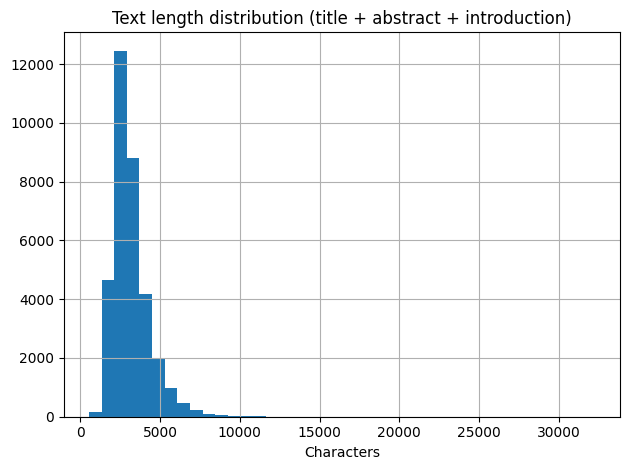

,filename,pmcid,doi,journal,year,authors,title,keywords,abstract,introduction,...,discussion,conclusion,tables,metadata_junk,kwd_lst,kwd_lst_cl,n_keywords,keywords_filtered,text,len
18404,PMC3477819.xml,PMC3477819,10.1007/s13225-011-0117-x,Fungal Divers Fungal Diversity,2011,Zhang Ying; Crous Pedro W.; Schoch Conrad L.; ...,Pleosporales,Generic type; Massarineae; Molecular phylogeny...,One hundred and five generic types of Pleospor...,Pleosporales is the largest order in the Dothi...,...,Molecular phylogenetic studies based on four t...,,References Circumscription of Luttrell -type c...,"\n[unmapped: synonyms]: Javaria Boise, J.R., A...","[Generic type, Massarineae, Molecular phylogen...","[generic type, massarineae, molecular phylogen...",6,"[molecular phylogeny, morphology, taxonomy]",Pleosporales One hundred and five generic type...,32267


In [2]:
df['text'] = (
    df['title'].fillna('')        + ' ' +
    df['abstract'].fillna('')     + ' ' +
    df['introduction'].fillna('')
)

print(f"Avg text length (chars): {df['text'].apply(len).mean():.0f}")
df['text'].apply(len).hist(bins=40)
plt.title('Text length distribution (title + abstract + introduction)')
plt.xlabel('Characters')
plt.tight_layout()
plt.show()

df['len']=df['text'].apply(len)
df_test = df[df['len'] > 20000].sort_values(by='len',ascending=False).head(1)
df_test#.apply(lambda x: len(str(x)))

## 2 - Target: MultiLabelBinarizer

Each article has a **list** of valid keywords (e.g. `["fret", "myosin", "actin"]`).
sklearn cannot work with lists directly — `MultiLabelBinarizer` converts them into
a **binary matrix** of shape `(n_articles, n_keywords)`:

```
             "actin"  "fret"  "myosin"  "diabetes"  ...   (~3000 columns)
Article  1:     1        1        1          0        ...
Article  2:     0        0        0          1        ...
```

> **Sparsity:** each article has ~3-5 keywords out of ~3000 possible → >99% of entries are 0.
> This is normal for multi-label text classification and handled efficiently by sparse matrices.

In [3]:
mlb = MultiLabelBinarizer(sparse_output=True)
y = mlb.fit_transform(df['keywords_filtered'])

print(f"Classes (unique valid keywords) : {len(mlb.classes_)}")
print(f"y shape                         : {y.shape}")
print(f"Avg keywords per article        : {y.sum(axis=1).mean():.2f}")
density = y.sum() / (y.shape[0] * y.shape[1])
print(f"Matrix density                  : {density:.5f}  ({density*100:.3f}% non-zero)")

Classes (unique valid keywords) : 2749
y shape                         : (34128, 2749)
Avg keywords per article        : 2.26
Matrix density                  : 0.00082  (0.082% non-zero)


## 3 - Train / Test Split

Standard 80/20 split. `random_state=42` ensures reproducibility across runs.

In [4]:
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    df['text'], y,
    test_size=0.2,
    random_state=42
)
print(f"Train : {X_train_raw.shape[0]} articles")
print(f"Test  : {X_test_raw.shape[0]} articles")

Train : 27302 articles
Test  : 6826 articles


## 4 - TF-IDF Vectorizer

**TF-IDF** (Term Frequency – Inverse Document Frequency) converts raw text into
a numeric matrix where each column is a word/bigram and each value reflects
how *characteristic* that term is for a given article:

- **TF** (term frequency): how often does the word appear in *this* article?
- **IDF** (inverse document frequency): how rare is the word *across all articles*?
  Common words like "the", "and" get low IDF → low weight.

| Parameter | Value | Reason |
|-----------|-------|--------|
| `max_features` | 50,000 | Keep only the 50k most frequent terms — RAM protection |
| `ngram_range` | (1, 2) | Include bigrams: `"cell death"` as one feature, not just `"cell"` + `"death"` |
| `sublinear_tf` | True | Use `log(1 + tf)` instead of raw count — dampens very frequent terms |
| `min_df` | 5 | Ignore terms appearing in fewer than 5 articles (noise reduction) |

In [5]:
tfidf = TfidfVectorizer(
    max_features=50_000,
    ngram_range=(1, 2),
    sublinear_tf=True,
    min_df=5
)

X_train_tfidf = tfidf.fit_transform(X_train_raw)
X_test_tfidf  = tfidf.transform(X_test_raw)

print(f"TF-IDF train matrix : {X_train_tfidf.shape}")
print(f"TF-IDF test matrix  : {X_test_tfidf.shape}")

TF-IDF train matrix : (27302, 50000)
TF-IDF test matrix  : (6826, 50000)


## 5 - LSA: Latent Semantic Analysis (TruncatedSVD)

TF-IDF treats every word independently — `"myocardial infarction"` and `"heart attack"`
have **zero similarity** even though they mean the same thing.

**LSA** applies Singular Value Decomposition (SVD) to the TF-IDF matrix,
compressing 50,000 word dimensions down to ~300 **semantic dimensions** that
capture co-occurrence patterns:

```
TF-IDF: (n_articles × 50,000)  →  LSA: (n_articles × 300)
```

Words that appear in similar contexts get similar vector representations.
This allows the model to generalise across synonyms and related terms.

> **`TruncatedSVD`** is used instead of full SVD because the input is a sparse matrix
> — full SVD would require dense memory (infeasible at this scale).

| Parameter | Value | Reason |
|-----------|-------|--------|
| `n_components` | 300 | Standard for biomedical text; captures most semantic variance |
| `random_state` | 42 | Reproducibility |

In [6]:
svd = TruncatedSVD(n_components=300, random_state=42)

X_train_lsa = svd.fit_transform(X_train_tfidf)
X_test_lsa  = svd.transform(X_test_tfidf)

explained = svd.explained_variance_ratio_.sum()
print(f"LSA train matrix          : {X_train_lsa.shape}")
print(f"Explained variance (300d) : {explained:.3f}  ({explained*100:.1f}%)")

LSA train matrix          : (27302, 300)
Explained variance (300d) : 0.156  (15.6%)


## 6 - Classifier: OneVsRest + LinearSVC + class_weight

### OneVsRestClassifier
For each of the ~3000 keywords, one independent **binary classifier** is trained:
*"does this article belong to keyword X — yes or no?"*
All classifiers run in parallel (`n_jobs=-1`).

### LinearSVC vs LogisticRegression
`LinearSVC` (Support Vector Classifier with linear kernel) consistently outperforms
Logistic Regression on sparse high-dimensional text data:
- Optimises a **margin** between classes rather than probability
- More robust to the extreme sparsity of TF-IDF / LSA features
- Typically 10–30% better F1 on text classification benchmarks

### CalibratedClassifierCV
`LinearSVC` has no `predict_proba()` — it only outputs hard class decisions.
`CalibratedClassifierCV` wraps it and adds **probability calibration** (Platt scaling),
which is required for our threshold tuning step.

### class_weight='balanced'
Our label matrix is extremely sparse — for a rare keyword appearing 11 times,
the classifier sees ~11 positive vs ~19,000 negative examples.
Without correction, the model learns to **always predict 0** (trivially correct 99.9% of the time).

`class_weight='balanced'` automatically upweights the minority class (positive examples)
proportionally to their rarity:

```
weight = n_samples / (2 × n_positive)
```

This forces the model to take rare keywords seriously.

| Parameter | Value | Reason |
|-----------|-------|--------|
| `C` | 1.0 | Regularisation strength. C=0.1 was too strong → model learned nothing |
| `max_iter` | 2000 | Enough iterations for convergence on large feature space |
| `class_weight` | balanced | Compensates for label imbalance across ~3000 keyword classes |
| `n_jobs` | -1 | Use all available CPU cores |

In [7]:
base_clf = CalibratedClassifierCV(
    LinearSVC(C=1.0, max_iter=2000, class_weight='balanced'),
    cv=3
)

clf = OneVsRestClassifier(base_clf, n_jobs=-1)
clf.fit(X_train_lsa, y_train)
print("Training complete.")

Training complete.


## 7 - Threshold Tuning

`predict_proba()` returns a probability score per keyword per article.
The default decision boundary of 0.5 is almost always too high for multi-label
classification with many rare classes — most keywords never reach 0.5.

We scan a range of thresholds and select the one maximising **micro-F1**.

> **micro-F1**: aggregates TP/FP/FN globally — frequent keywords dominate.
> **macro-F1**: averages F1 per keyword equally — rare keywords pull it down.

In [8]:
proba = clf.predict_proba(X_test_lsa)

thresholds = [0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.5]
results = []
for t in thresholds:
    y_pred = (proba >= t).astype(int)
    f1_mi  = f1_score(y_test, y_pred, average='micro', zero_division=0)
    f1_ma  = f1_score(y_test, y_pred, average='macro', zero_division=0)
    n_avg  = y_pred.sum(axis=1).mean()
    results.append({'threshold': t, 'f1_micro': f1_mi, 'f1_macro': f1_ma, 'avg_labels': n_avg})
    print(f"t={t:.2f}  micro-F1={f1_mi:.3f}  macro-F1={f1_ma:.3f}  avg_labels={n_avg:.1f}")

df_res = pd.DataFrame(results)
best_t = df_res.loc[df_res['f1_micro'].idxmax(), 'threshold']
print(f"\nBest threshold: {best_t}")

t=0.05  micro-F1=0.299  macro-F1=0.183  avg_labels=4.0
t=0.10  micro-F1=0.306  macro-F1=0.156  avg_labels=2.2
t=0.15  micro-F1=0.287  macro-F1=0.130  avg_labels=1.5
t=0.20  micro-F1=0.265  macro-F1=0.111  avg_labels=1.1
t=0.25  micro-F1=0.238  macro-F1=0.093  avg_labels=0.8
t=0.30  micro-F1=0.214  macro-F1=0.080  avg_labels=0.7
t=0.35  micro-F1=0.189  macro-F1=0.066  avg_labels=0.5
t=0.40  micro-F1=0.167  macro-F1=0.055  avg_labels=0.4
t=0.50  micro-F1=0.127  macro-F1=0.038  avg_labels=0.3

Best threshold: 0.1


## 8 - Final Evaluation

Micro-F1 : 0.306
Macro-F1 : 0.156


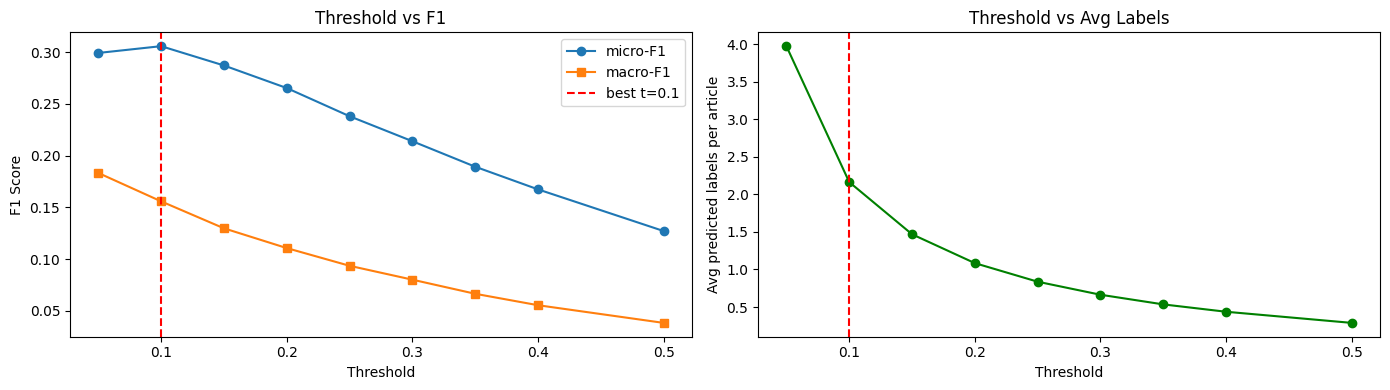

In [ ]:
y_pred_best = (proba >= best_t).astype(int)

micro = f1_score(y_test, y_pred_best, average='micro', zero_division=0)
macro = f1_score(y_test, y_pred_best, average='macro', zero_division=0)
print(f"Micro-F1 : {micro:.3f}")
print(f"Macro-F1 : {macro:.3f}")

# F1 curve
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(df_res['threshold'], df_res['f1_micro'], marker='o', label='micro-F1')
axes[0].plot(df_res['threshold'], df_res['f1_macro'], marker='s', label='macro-F1')
axes[0].axvline(best_t, color='red', linestyle='--', label=f'best t={best_t}')
axes[0].set_xlabel('Threshold')
axes[0].set_ylabel('F1 Score')
axes[0].set_title('Threshold vs F1')
axes[0].legend()

axes[1].plot(df_res['threshold'], df_res['avg_labels'], marker='o', color='green')
axes[1].axvline(best_t, color='red', linestyle='--')
axes[1].set_xlabel('Threshold')
axes[1].set_ylabel('Avg predicted labels per article')
axes[1].set_title('Threshold vs Avg Labels')

fig.savefig("plots/f1_threshold_baseline_2_improved.png", dpi=150, bbox_inches='tight')
plt.tight_layout()
plt.show()

In [ ]:
# Plot 1: F1 Curves
fig1, ax1 = plt.subplots(figsize=(7, 4))
ax1.plot(df_res['threshold'], df_res['f1_micro'], marker='o', label='micro-F1')
ax1.plot(df_res['threshold'], df_res['f1_macro'], marker='s', label='macro-F1')
ax1.axvline(best_t, color='red', linestyle='--', label=f'best t={best_t}')
ax1.set_xlabel('Threshold')
ax1.set_ylabel('F1 Score')
ax1.set_title('Threshold vs F1')
ax1.legend()
fig1.savefig("plots/f1_threshold.png", dpi=150, bbox_inches='tight')
plt.show()

# Plot 2: Avg Labels
fig2, ax2 = plt.subplots(figsize=(7, 4))
ax2.plot(df_res['threshold'], df_res['avg_labels'], marker='o', color='green')
ax2.axvline(best_t, color='red', linestyle='--', label=f'best t={best_t}')
ax2.set_xlabel('Threshold')
ax2.set_ylabel('Avg predicted labels per article')
ax2.set_title('Threshold vs Avg Labels')
ax2.legend()
fig2.savefig("plots/avg_labels_threshold.png", dpi=150, bbox_inches='tight')
plt.show()

## 9 - Example Predictions

In [10]:
for i in range(5):
    true_kws = mlb.inverse_transform(y_test[i])[0]
    pred_kws = mlb.inverse_transform(y_pred_best[i:i+1])[0]
    print(f"--- Article {i} ---")
    print(f"  TRUE : {sorted(true_kws)}")
    print(f"  PRED : {sorted(pred_kws)}")
    print()

--- Article 0 ---
  TRUE : ['learning curve']
  PRED : []

--- Article 1 ---
  TRUE : ['craniotomy']
  PRED : []

--- Article 2 ---
  TRUE : ['dog', 'escherichia coli', 'urinary tract infection']
  PRED : ['escherichia coli']

--- Article 3 ---
  TRUE : ['cns central nervous system', 'il interleukin', 'ko knockout', 'microglia', 'pfa paraformaldehyde', 'tnf tumour necrosis factor', 'wt wild type']
  PRED : []

--- Article 4 ---
  TRUE : ['kidney', 'liver']
  PRED : []



## 10 - Results Summary

| Experiment | micro-F1 | macro-F1 | Note |
|------------|----------|----------|------|
| title+abstract, LR C=1.0 | 0.205 | 0.031 | Baseline v0 |
| title+abstract+intro, LR C=0.1 | 0.006 | 0.000 | C too small |
| title+abstract+intro, LinearSVC + LSA + balanced | 0.306 | 0.156 | 

## 11 - Save Model (optional)

In [12]:
SAVE_MODEL = True  # set True to persist

if SAVE_MODEL:
    import pickle
    model_dir = PROJECT_ROOT / 'models'
    model_dir.mkdir(exist_ok=True)
    with open(model_dir / 'baseline_v1_clf.pkl', 'wb') as f:
        pickle.dump({
            'clf': clf, 'tfidf': tfidf, 'svd': svd,
            'mlb': mlb, 'threshold': best_t
        }, f)
    print(f"Saved to {model_dir / 'baseline_v1_clf.pkl'}")
else:
    print("SAVE_MODEL = False — nothing written.")

Saved to c:\Users\<user>\bootcamps\CAPSTONE\Capstone1-text-prediction-for-scientific-papers\models\baseline_v1_clf.pkl
